# Customer Churn Prediction

## Project Overview

Customer churn is a major challenge for subscription-based businesses. Retaining existing customers is often more cost-effective than acquiring new ones.

In this project, I built and evaluated multiple machine learning models to predict customer churn using the IBM Telco Customer Churn dataset. The goal was to identify the factors contributing to churn and develop a predictive model capable of identifying customers at risk of leaving.

## Modelling Workflow

1. Data Cleaning and Preprocessing
2. Exploratory Data Analysis
3. Model Training
   - Logistic Regression
   - Random Forest
   - CatBoost
   - XGBoost
4. Hyperparameter Tuning
5. Threshold Optimisation
6. Feature Importance Analysis
7. Business Insights and Recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


np.random.seed(42)

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/refs/heads/master/data/Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(f"Samples in the dataframe: {df.shape[0]}")
print(f"Columns in the dataframe: {df.shape[1]}")

print(f"List of features and there datatypes:")
for idx, feature in enumerate(list(df.columns)):
    print(f"{idx+1}. {feature}: {str(df[feature].dtype)}")

Samples in the dataframe: 7043
Columns in the dataframe: 21
List of features and there datatypes:
1. customerID: str
2. gender: str
3. SeniorCitizen: int64
4. Partner: str
5. Dependents: str
6. tenure: int64
7. PhoneService: str
8. MultipleLines: str
9. InternetService: str
10. OnlineSecurity: str
11. OnlineBackup: str
12. DeviceProtection: str
13. TechSupport: str
14. StreamingTV: str
15. StreamingMovies: str
16. Contract: str
17. PaperlessBilling: str
18. PaymentMethod: str
19. MonthlyCharges: float64
20. TotalCharges: str
21. Churn: str


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
def get_random_idx(dataset):
    return int(np.random.randint(0, len(dataset)))

# Inspecting a random sample
random_sample = df.iloc[get_random_idx(df), :]
for k,v in random_sample.items():
    print(f"{k}: {v}")

customerID: 4795-UXVCJ
gender: Male
SeniorCitizen: 0
Partner: No
Dependents: No
tenure: 26
PhoneService: Yes
MultipleLines: No
InternetService: No
OnlineSecurity: No internet service
OnlineBackup: No internet service
DeviceProtection: No internet service
TechSupport: No internet service
StreamingTV: No internet service
StreamingMovies: No internet service
Contract: One year
PaperlessBilling: No
PaymentMethod: Credit card (automatic)
MonthlyCharges: 19.8
TotalCharges: 457.3
Churn: No


In [6]:
# customerId is not needed
df = df.drop(columns=['customerID'])

# senior citizen in int64, convert to object as it is a categorical variable
df['SeniorCitizen'] = df['SeniorCitizen'].astype('object')

# total charges is string, convert into float
df['TotalCharges'] = df['TotalCharges'].apply(lambda x: x.strip() if len(x.strip()) else '0.0').astype('float',errors="raise")

In [7]:
# checking for null and duplicates
print(df.isna().sum() / len(df) * 100)
print("=="*40)#

print("Duplicates",df.duplicated().sum())

gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64
Duplicates 22


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   object 
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [9]:
TARGET = "Churn"
num_features = [col for col in df.select_dtypes(include=np.number).columns.tolist() if col != TARGET]
cat_features = [col for col in df.select_dtypes(exclude=np.number).columns.tolist() if col != TARGET]

print(f"Numerical features: {num_features}")
print(f"Categorical features: {cat_features}")
print(f"Target feature: {TARGET}")

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Target feature: Churn


In [10]:
# numerical summary
print("Numerical summary")
print(df[num_features].describe().T)

Numerical summary
                 count         mean          std    min     25%      50%  \
tenure          7043.0    32.371149    24.559481   0.00    9.00    29.00   
MonthlyCharges  7043.0    64.761692    30.090047  18.25   35.50    70.35   
TotalCharges    7043.0  2279.734304  2266.794470   0.00  398.55  1394.55   

                    75%      max  
tenure            55.00    72.00  
MonthlyCharges    89.85   118.75  
TotalCharges    3786.60  8684.80  


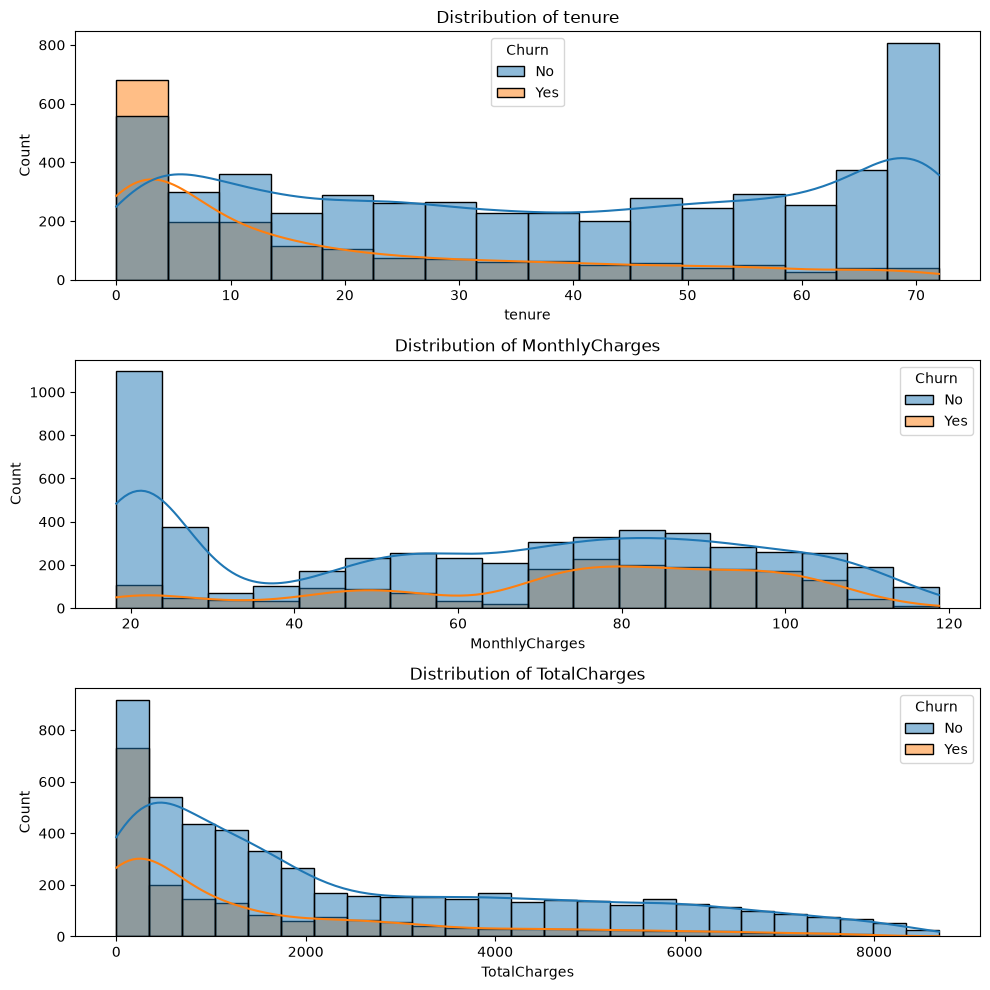

In [11]:
# distribution of numerical features

fig, axes = plt.subplots(len(num_features),1,figsize=(10,10))
axes=axes.flatten()
for idx, col in enumerate(num_features):
    sns.histplot(data=df,x=col,ax=axes[idx],kde=True, hue=TARGET)
    axes[idx].set_title(f"Distribution of {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Count")
plt.tight_layout()
plt.show()

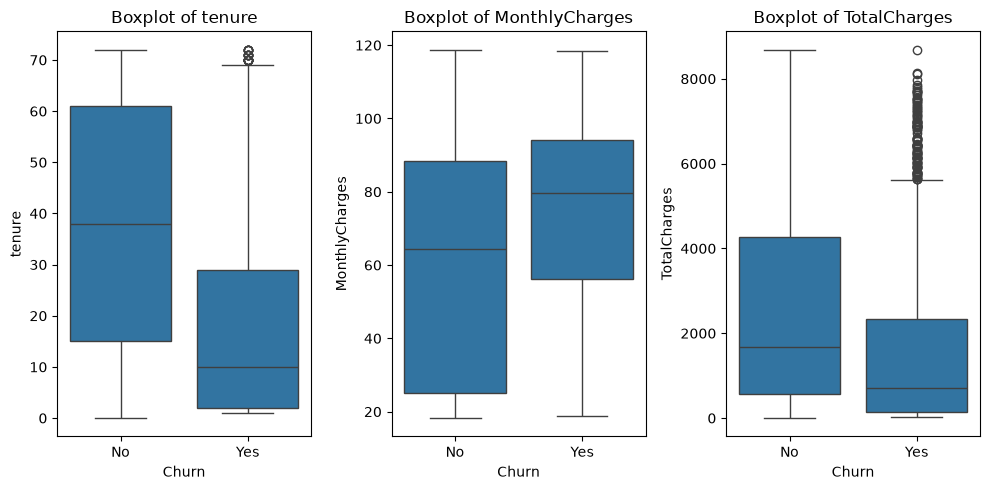

In [12]:
fig,axes = plt.subplots(1, len(num_features), figsize=(10,5))
axes = axes.flatten()
for idx,col in enumerate(num_features):
    sns.boxplot(data=df,x=TARGET,y=col,ax=axes[idx])
    axes[idx].set_title(f"Boxplot of {col}")
    axes[idx].set_xlabel(TARGET)
    axes[idx].set_ylabel(col)
plt.tight_layout()
plt.show()


                  tenure  MonthlyCharges  TotalCharges
tenure          1.000000        0.247900      0.826178
MonthlyCharges  0.247900        1.000000      0.651174
TotalCharges    0.826178        0.651174      1.000000


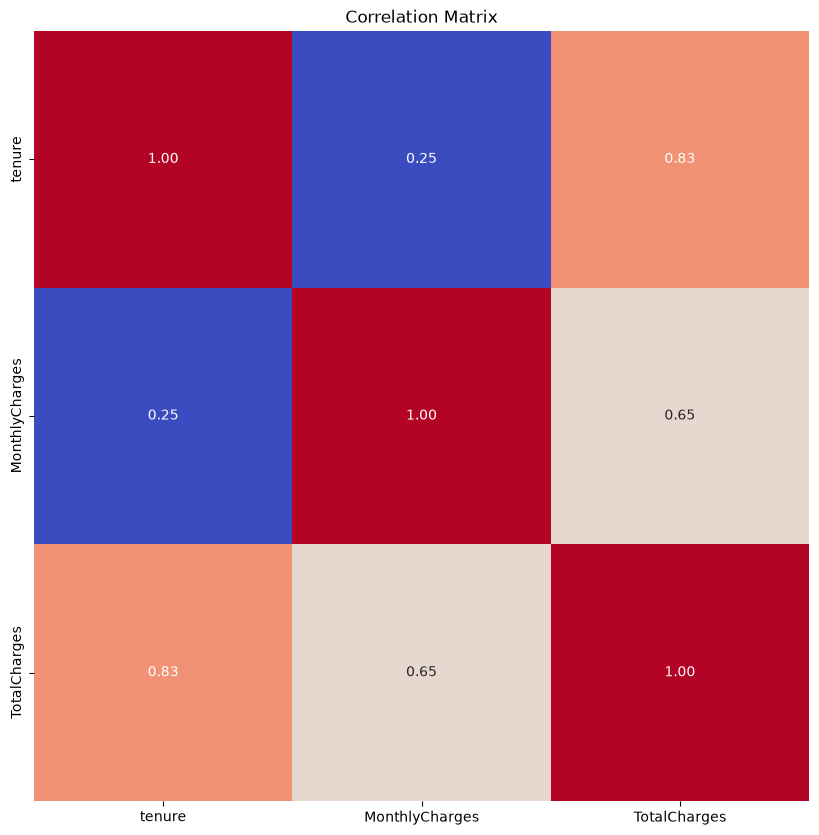

In [13]:
corr_matrix = df[num_features].corr()
print(corr_matrix)

plt.figure(figsize=(10,10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=False)
plt.title('Correlation Matrix')
plt.show()

In [14]:
# Categorical analysis
print("Categorical Summary")
for col in cat_features:
    print(f"{col}:")
    print(dict(df[col].value_counts()))
    print("=="*40)

Categorical Summary
gender:
{'Male': np.int64(3555), 'Female': np.int64(3488)}
SeniorCitizen:
{0: np.int64(5901), 1: np.int64(1142)}
Partner:
{'No': np.int64(3641), 'Yes': np.int64(3402)}
Dependents:
{'No': np.int64(4933), 'Yes': np.int64(2110)}
PhoneService:
{'Yes': np.int64(6361), 'No': np.int64(682)}
MultipleLines:
{'No': np.int64(3390), 'Yes': np.int64(2971), 'No phone service': np.int64(682)}
InternetService:
{'Fiber optic': np.int64(3096), 'DSL': np.int64(2421), 'No': np.int64(1526)}
OnlineSecurity:
{'No': np.int64(3498), 'Yes': np.int64(2019), 'No internet service': np.int64(1526)}
OnlineBackup:
{'No': np.int64(3088), 'Yes': np.int64(2429), 'No internet service': np.int64(1526)}
DeviceProtection:
{'No': np.int64(3095), 'Yes': np.int64(2422), 'No internet service': np.int64(1526)}
TechSupport:
{'No': np.int64(3473), 'Yes': np.int64(2044), 'No internet service': np.int64(1526)}
StreamingTV:
{'No': np.int64(2810), 'Yes': np.int64(2707), 'No internet service': np.int64(1526)}
Stream

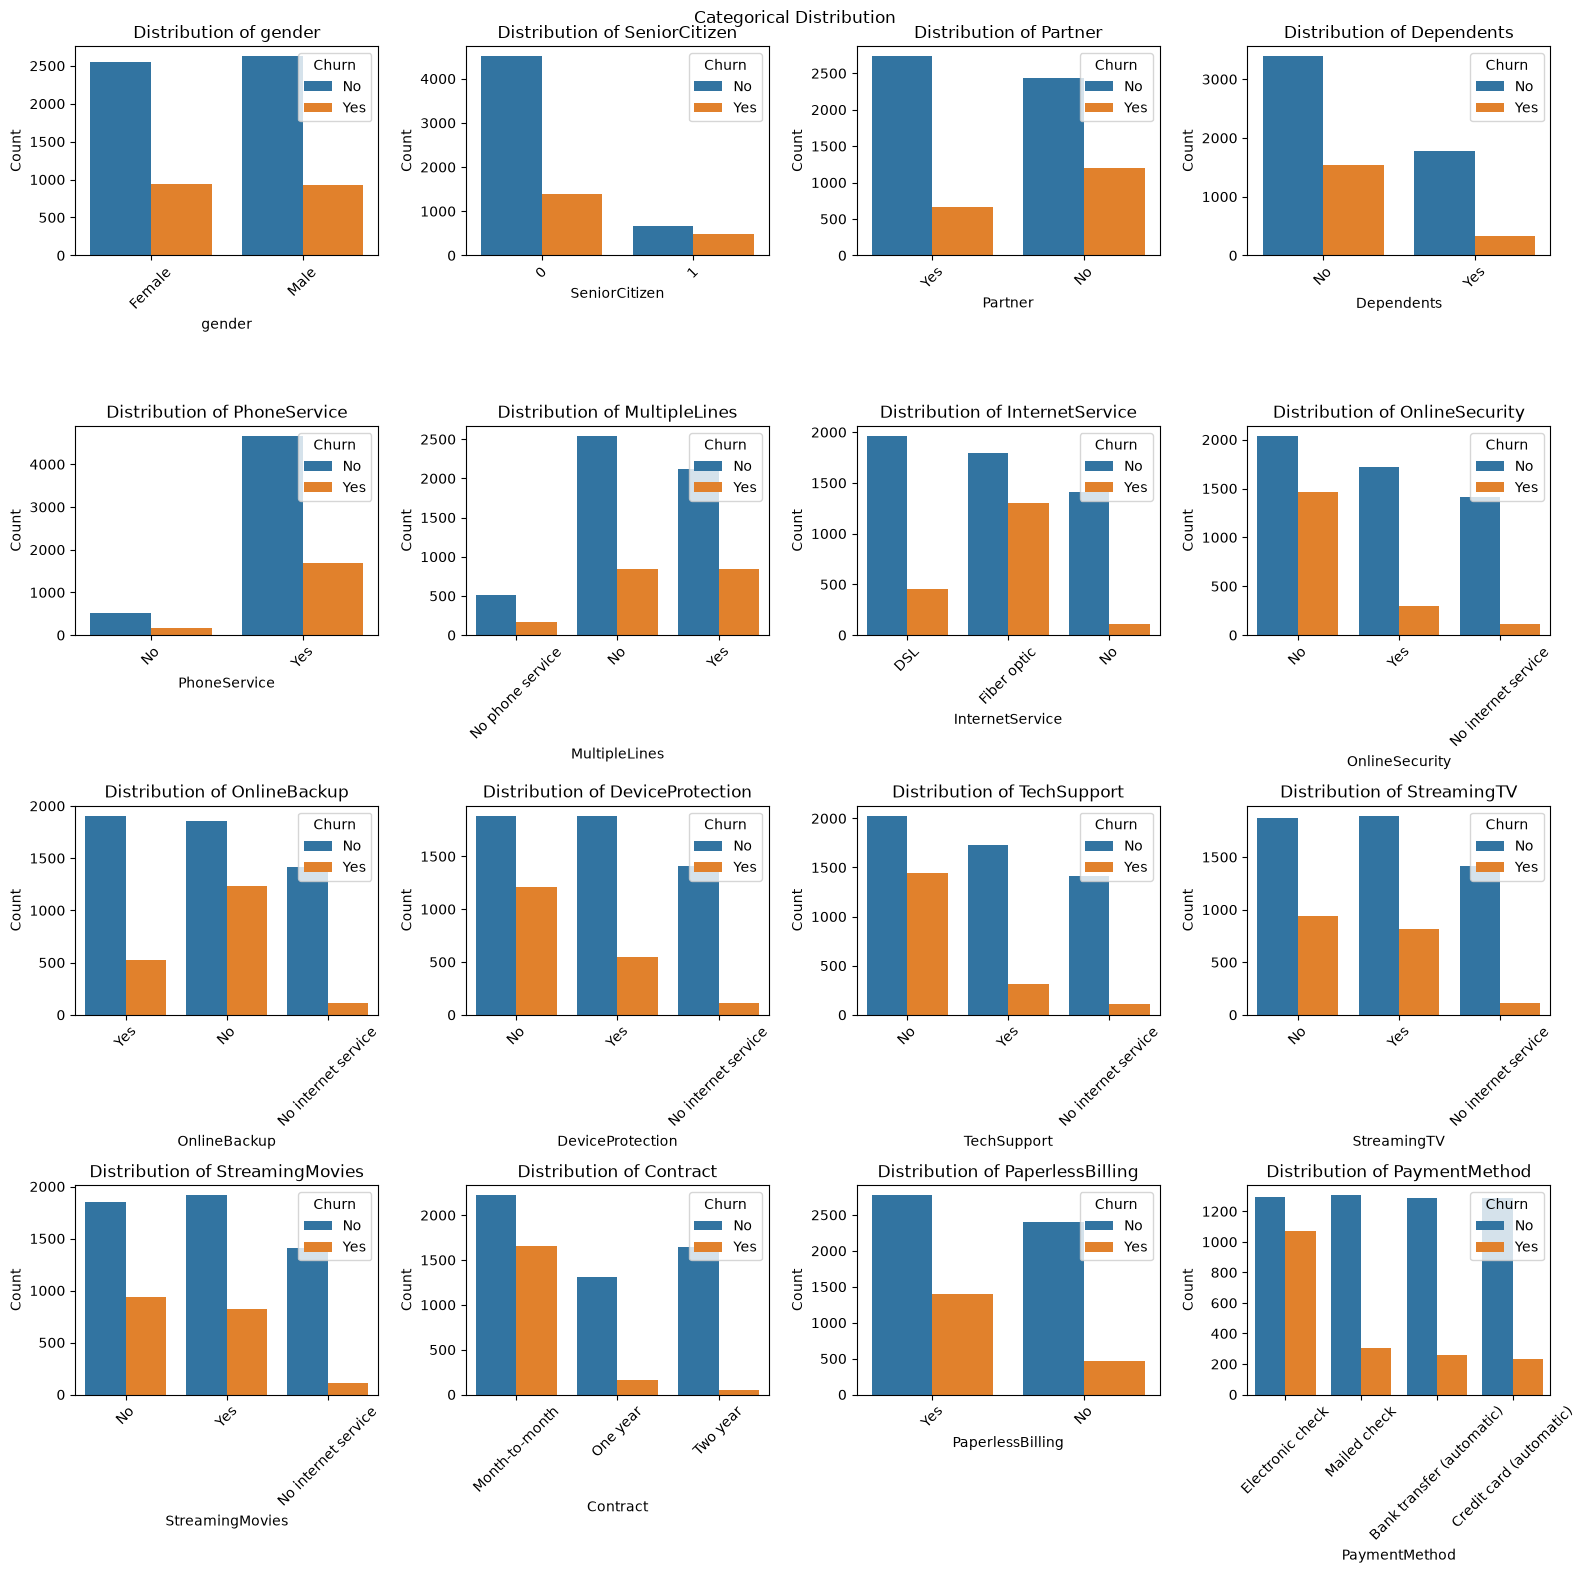

In [15]:
# categorical distribution 16 features 4X4 plot
fig,axes = plt.subplots(4,4,figsize=(16,16))
axes = axes.flatten()
plt.suptitle("Categorical Distribution")
for idx, col in enumerate(cat_features):
    sns.countplot(data=df,x=col,ax=axes[idx], hue=TARGET)
    axes[idx].set_title(f"Distribution of {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Count")
    axes[idx].legend(title=TARGET, loc='upper right')
    axes[idx].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

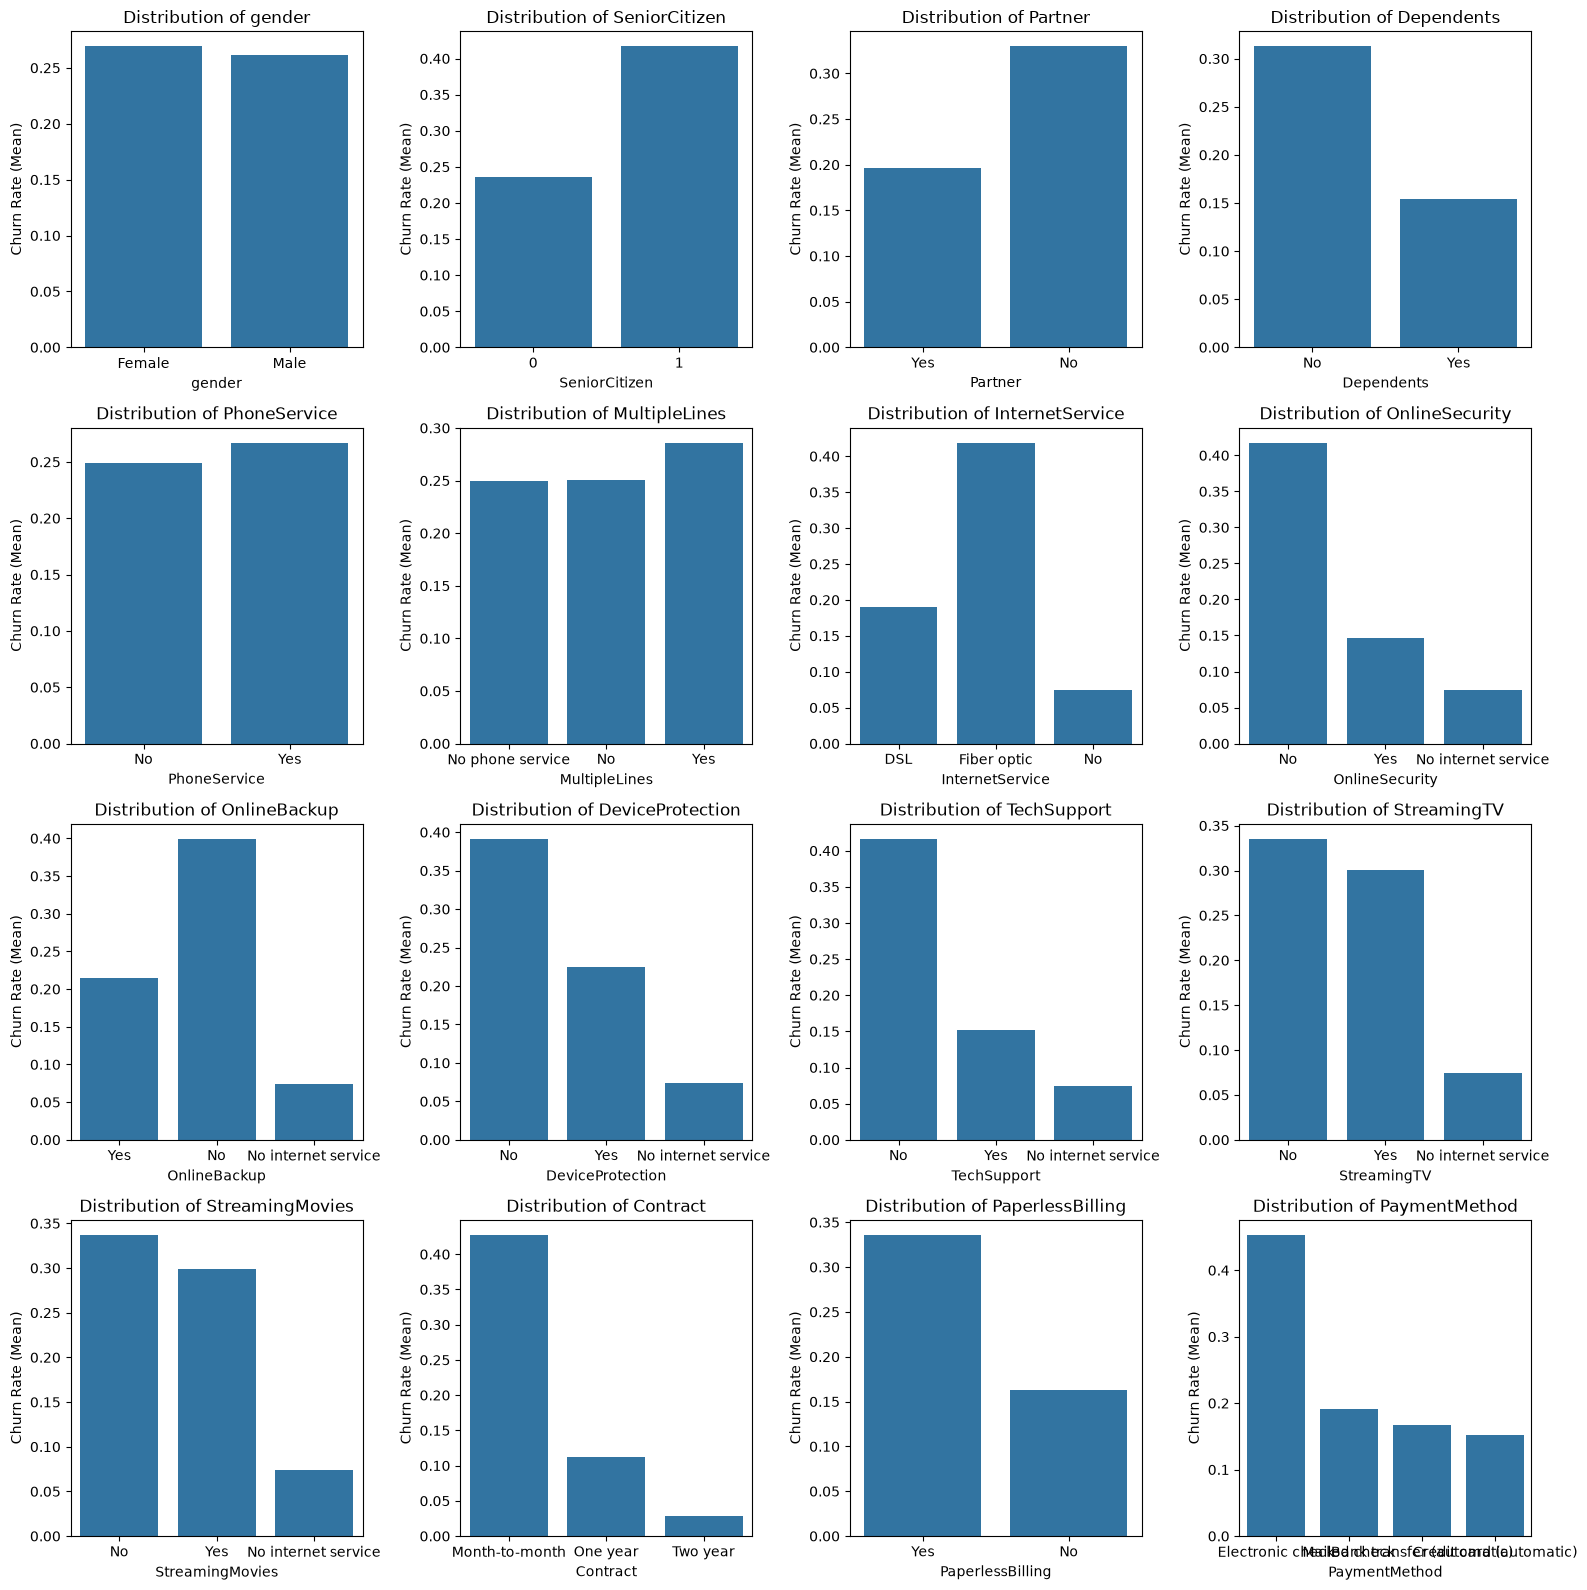

In [16]:
fig, axes = plt.subplots(4,4, figsize=(16,16))
axes = axes.flatten()

for idx, col in enumerate(cat_features):
    sns.barplot(
        # data=df,
        x=df[col],
        y=df[TARGET].map({'Yes': 1, 'No': 0}),
        ax = axes[idx],
        # hue=TARGET,
        errorbar=None,
        # order=df[col].value_counts().index
    )
    axes[idx].set_title(f"Distribution of {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Churn Rate (Mean)")
    # axes[idx].legend(title=TARGET, loc='upper right')
plt.tight_layout()
plt.show()

Churn
No     5174
Yes    1869
Name: count, dtype: int64
distribution in percentage: {'No': np.float64(0.7346301292063041), 'Yes': np.float64(0.2653698707936959)}


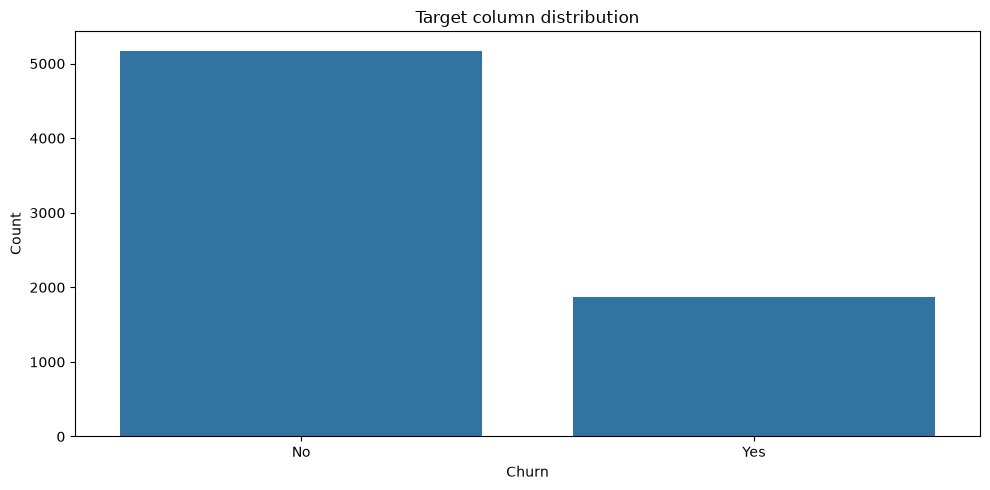

In [17]:
# Target column distribution
print(df[TARGET].value_counts())
distribution = {k: v/len(df) for k,v in dict(df[TARGET].value_counts()).items()}
print(f"distribution in percentage: {distribution}")

fig, axes = plt.subplots(1,1,figsize=(10,5))

axes = sns.countplot(x=TARGET,data=df)
axes.set_title("Target column distribution")
axes.set_xlabel(TARGET)
axes.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier


In [19]:
X = df.drop(columns=[TARGET])
y = df[TARGET].map({"Yes":1,"No":0})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [20]:
numerical_preprocessor = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_preprocessor = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', numerical_preprocessor, num_features),
        ('categorical', categorical_preprocessor, cat_features)
    ]
)

final_pipeline = make_pipeline(clone(preprocessor), LogisticRegression(max_iter=10000, random_state=42))
final_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_thr

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



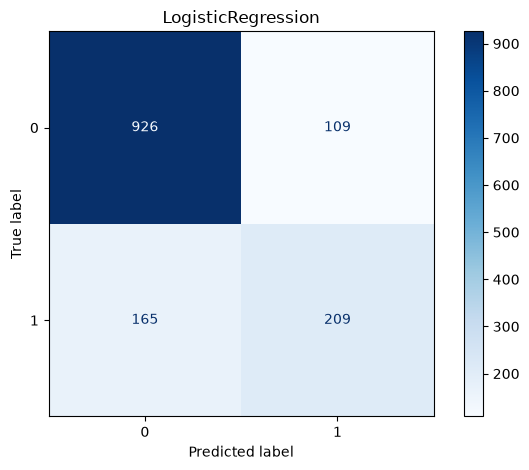

              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



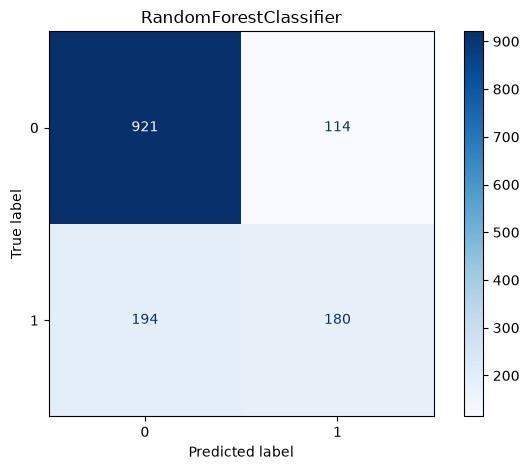

              precision    recall  f1-score   support

    No Churn       0.83      0.87      0.85      1035
       Churn       0.59      0.52      0.55       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



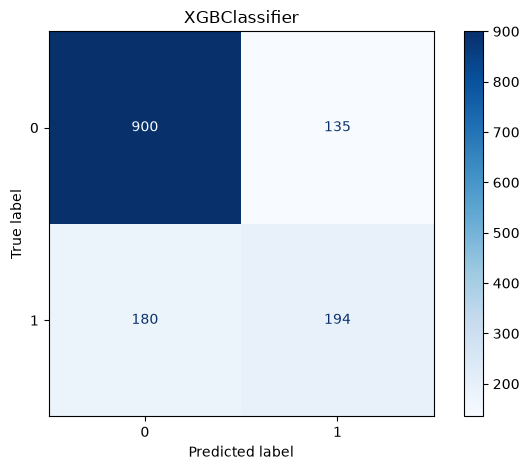

In [21]:
def evaluate_model(model_name, pipe, X_train, X_test, y_train, y_test):
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:,1] # for roc auc score

    print(classification_report(y_test, y_pred,target_names=["No Churn", "Churn"],zero_division=0))

    result = {
        "model_name": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, y_proba)
    }

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        cmap="Blues"
    )
    plt.title(model_name)
    plt.tight_layout()
    plt.show()

    return result


models = {
    "LogisticRegression": LogisticRegression(max_iter=10000, random_state=42),
    # "LogisticRegression(balanced)": LogisticRegression(max_iter=10000, random_state=42, class_weight="balanced"),
    "RandomForestClassifier": RandomForestClassifier(random_state=42),
    # "CatBoostClassifier": CatBoostClassifier(random_state=42, verbose=0),
    "XGBClassifier": XGBClassifier(random_state=42, eval_metric="logloss")
}


# baseline models with default params
trained_models = {}
results = []
for model_name, model in models.items():
    pipe = make_pipeline(clone(preprocessor), model)

    # for cross validation
    # scores = cross_val_score(
    #     pipe,
    #     X_train,
    #     y_train,
    #     cv=5,
    #     scoring="f1"
    # )
    # print("scores", scores.mean())

    result = evaluate_model(model_name, pipe, X_train, X_test, y_train, y_test)

    results.append(result)
    trained_models[model_name] = pipe

In [22]:
results_df = pd.DataFrame(results)
print(np.round(results_df,2))

               model_name  accuracy  precision  recall  f1_score  roc_auc
0      LogisticRegression      0.81       0.66    0.56      0.60     0.84
1  RandomForestClassifier      0.78       0.61    0.48      0.54     0.82
2           XGBClassifier      0.78       0.59    0.52      0.55     0.82


              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409

ROC-AUC: 0.8425831202046035


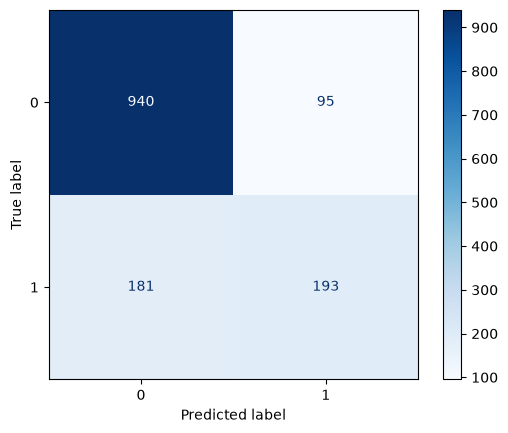

In [ ]:
X_cat_train = X_train.copy()
X_cat_test = X_test.copy()

# Ensure categorical columns contain consistent strings
for col in cat_features:

    X_cat_train[col] = (
        X_cat_train[col]
        .fillna("Unknown")
        .astype(str)
    )

    X_cat_test[col] = (
        X_cat_test[col]
        .fillna("Unknown")
        .astype(str)
    )

cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0
)

cat_model.fit(
    X_cat_train,
    y_train,
    cat_features=cat_features
)

cat_probabilities = cat_model.predict_proba(
    X_cat_test
)[:, 1]

cat_predictions = (cat_probabilities >= 0.5).astype(int)

print(classification_report(y_test, cat_predictions))
print("ROC-AUC:", roc_auc_score(y_test, cat_probabilities))
result = {
        "model_name": 'CatBoostClassifier',
        "accuracy": accuracy_score(y_test, cat_predictions),
        "precision": precision_score(
            y_test, cat_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, cat_predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, cat_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, cat_probabilities)
    }

ConfusionMatrixDisplay.from_predictions(
    y_test,
    cat_predictions,
    cmap="Blues"
)
plt.show()


In [24]:
results_df.loc[len(results_df)] = result
print(np.round(results_df,2))

               model_name  accuracy  precision  recall  f1_score  roc_auc
0      LogisticRegression      0.81       0.66    0.56      0.60     0.84
1  RandomForestClassifier      0.78       0.61    0.48      0.54     0.82
2           XGBClassifier      0.78       0.59    0.52      0.55     0.82
3      CatBoostClassifier      0.80       0.67    0.52      0.58     0.84


## Hyperparameter Tuning

GridSearchCV was applied to Logistic Regression using 5-fold cross-validation. The search explored different regularisation strengths (C) and class weighting strategies.

The best-performing configuration was selected based on F1-score and used for the final evaluation.

In [25]:
param_grid = {
    "logisticregression__C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ],
    "logisticregression__class_weight": [
        None,
        "balanced"
    ],
    "logisticregression__solver": [
        "liblinear"
    ]
}

grid = GridSearchCV(
    estimator=make_pipeline(
        clone(preprocessor),
        LogisticRegression(random_state=42, max_iter=10000)
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    # n_jobs=-1
)

# running the search grid
grid.fit(X_train, y_train)
print("Best Params:")
print(grid.best_params_)

print("\nBest CV F1:")
print(grid.best_score_)

Best Params:
{'logisticregression__C': 0.1, 'logisticregression__class_weight': 'balanced', 'logisticregression__solver': 'liblinear'}

Best CV F1:
0.6326409296769036


In [26]:
# Examine all results
grid_results = pd.DataFrame(grid.cv_results_)

grid_results[
    [
        "mean_test_score",
        "param_logisticregression__C",
        "param_logisticregression__class_weight"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
).head(10)

,mean_test_score,param_logisticregression__C,param_logisticregression__class_weight
5,0.632641,0.100,balanced
7,0.632176,1.000,balanced
9,0.631464,10.000,balanced
11,0.631017,100.000,balanced
3,0.629044,0.010,balanced
1,0.615360,0.001,balanced
10,0.599371,100.000,NaN
8,0.598719,10.000,NaN
6,0.597241,1.000,NaN
4,0.591022,0.100,NaN


In [27]:
# Evaluate the Best Model on Test Set
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

print("ROC AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC AUC: 0.8410214678756879


In [28]:
# performing threshold optimization

oof_proba = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

threshold_results = []
for threshold in np.arange(0.2, 0.8, 0.05):
    t = round(float(threshold), 2)
    # y_pred = (y_proba >= threshold).astype(int)
    oof_pred = (oof_proba >= t).astype(int)
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_train, oof_pred),
        "recall": recall_score(y_train, oof_pred),
        "f1_score": f1_score(y_train, oof_pred)
    })
    threshold_df = pd.DataFrame(threshold_results)

threshold_df = pd.DataFrame(threshold_results)
best_threshold = threshold_df.loc[threshold_df["f1_score"].idxmax(), "threshold"]
print(f"Optimal CV Threshold: {best_threshold:.2f}")

# 3. Evaluate once on the held-out test set using the chosen threshold
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred_opt = (y_proba >= best_threshold).astype(int)

print(f"\nTest Set Classification Report (Threshold = {best_threshold:.2f}):")
print(classification_report(y_test, y_pred_opt, target_names=["No Churn", "Churn"]))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

threshold_df.sort_values(
    by="f1_score",
    ascending=False
).head()

Optimal CV Threshold: 0.50

Test Set Classification Report (Threshold = 0.50):
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC AUC: 0.8410214678756879


,threshold,precision,recall,f1_score
6,0.50,0.522004,0.801338,0.632190
7,0.55,0.542226,0.755853,0.631461
8,0.60,0.570808,0.703679,0.630318
9,0.65,0.602580,0.656187,0.628242
5,0.45,0.492868,0.832107,0.619059


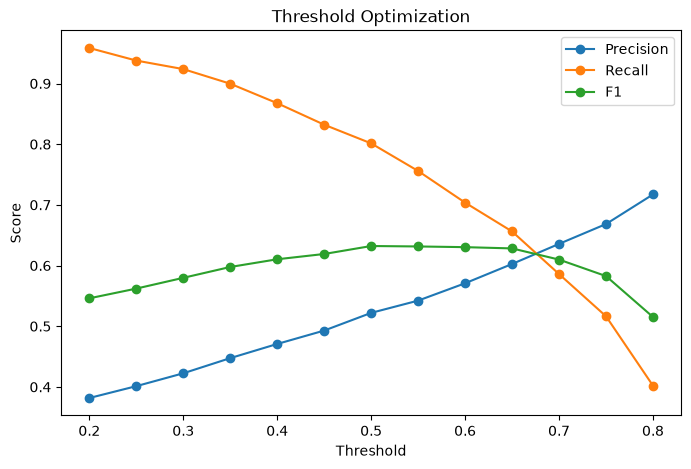

In [29]:
# visualize threshold tuning
plt.figure(figsize=(8,5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")
plt.legend()

plt.show()

In [30]:
# extract important features
best_model = grid.best_estimator_
raw_feature_names = (
    best_model.named_steps["columntransformer"]
    .get_feature_names_out()
)

# clean feature names
feature_names = [name.split("__", 1)[-1] for name in raw_feature_names]

coefficients = (
    best_model.named_steps["logisticregression"]
    .coef_[0]
)
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df = coef_df.sort_values(
    "coefficient",
    ascending=False
)

coef_df.head(15)

,feature,coefficient
32,Contract_Month-to-month,0.604664
35,PaperlessBilling_Yes,0.318520
12,InternetService_Fiber optic,0.302100
2,TotalCharges,0.292195
38,PaymentMethod_Electronic check,0.229963
14,OnlineSecurity_No,0.179811
23,TechSupport_No,0.147964
4,SeniorCitizen_1,0.147499
1,MonthlyCharges,0.147290
31,StreamingMovies_Yes,0.064634


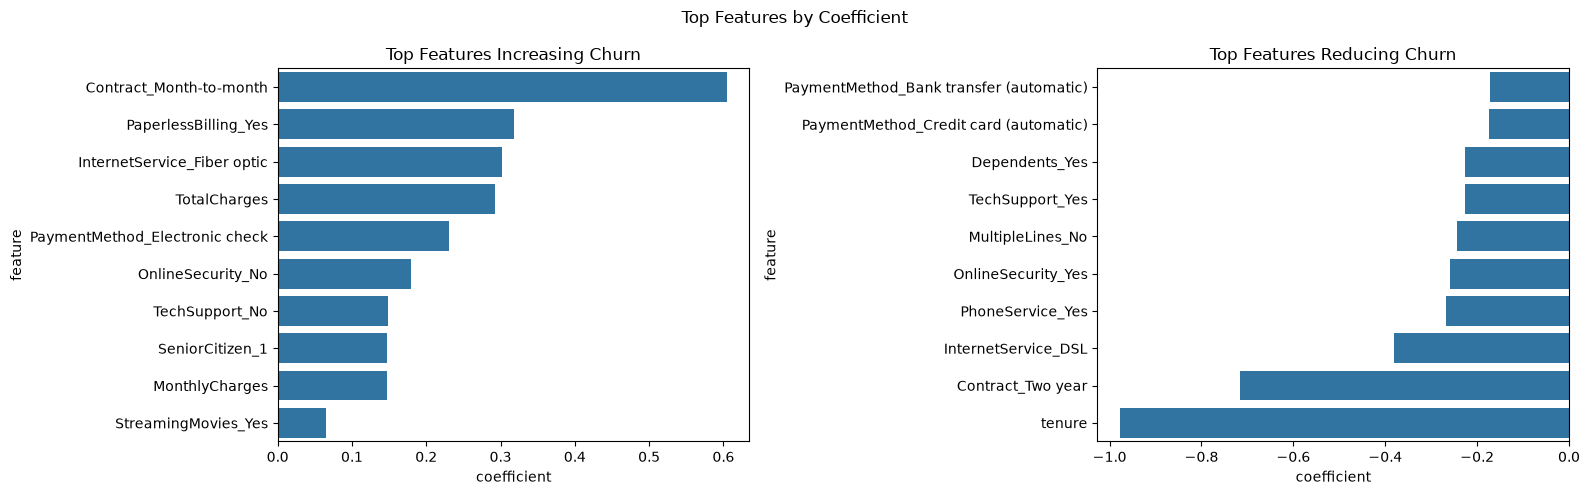

In [31]:
# plotting top features
top_positive = coef_df.head(10)
top_negative = coef_df.tail(10)

fig,axes = plt.subplots(1,2,figsize=(16,5))
axes=axes.flatten()
sns.barplot(
    data=top_positive,
    x="coefficient",
    y="feature",
    ax=axes[0]
)
axes[0].set_title("Top Features Increasing Churn")

sns.barplot(
    data=top_negative,
    x="coefficient",
    y="feature",
    ax=axes[1]
)
axes[1].set_title("Top Features Reducing Churn")

plt.suptitle("Top Features by Coefficient")
plt.tight_layout()
plt.show()

#Findings

###Customers More Likely to Churn

The logistic regression model identified several factors that are strongly associated with customer churn:

- Customers on month-to-month contracts were the most likely to churn, making contract type one of the strongest predictors of customer retention.
- Customers using fibre optic internet service exhibited a higher likelihood of churning compared to customers using DSL services.
- Customers who paid using electronic checks showed an increased tendency to leave the service.
- The absence of online security and technical support services was associated with higher churn rates.
- Customers with higher monthly charges were also more likely to churn.
###Customers Less Likely to Churn

Several factors were found to be associated with lower churn risk:

- Customers with longer tenure were significantly less likely to leave the company.
- Customers on two-year contracts demonstrated much higher retention rates compared to month-to-month customers.
- Customers using DSL internet services were generally less likely to churn.
- Customers subscribed to technical support and online security services showed stronger customer retention.
- Customers using automatic credit card payments exhibited lower churn rates than those using electronic checks.
###Key Insights
Contract type was the most influential categorical feature in predicting customer churn.
Customer tenure was the strongest numerical feature associated with customer retention.
Customers who make a greater long-term commitment through longer contracts tend to remain with the company for longer periods.
Additional services such as technical support and online security appear to contribute positively to customer retention.
Payment method and internet service type also play an important role in determining churn behaviour.
###Model Performance Summary

Four machine learning models were evaluated: Logistic Regression, Random Forest, CatBoost, and XGBoost.

| Model Name               | Accuracy | Precision | Recall | F1 Score | ROC AUC |
|--------------------------|----------|-----------|--------|----------|---------|
| LogisticRegression       | 0.81     | 0.66      | 0.56   | 0.60     | 0.84    |
| RandomForestClassifier   | 0.78     | 0.61      | 0.48   | 0.54     | 0.82    |
| XGBClassifier            | 0.78     | 0.59      | 0.52   | 0.55     | 0.82    |
| CatBoostClassifier       | 0.80     | 0.67      | 0.52   | 0.58     | 0.84    |


The balanced Logistic Regression model achieved the highest F1 score while maintaining a strong ROC-AUC score. Threshold optimisation further improved the balance between precision and recall, making Logistic Regression the final selected model.

###Conclusion

This project demonstrated that customer churn can be predicted effectively using customer demographics, account information, service subscriptions, and billing characteristics. Among all models tested, Logistic Regression provided the best overall performance while remaining highly interpretable. The analysis highlighted contract type, tenure, internet service type, payment method, and support-related services as the most important drivers of customer churn.

### Limitations

- The dataset represents a single telecommunications company and may not generalise to all businesses.
- The project relies only on the available customer attributes and does not include customer interaction history or behavioural data.
- More advanced feature engineering and ensemble methods could potentially improve performance further.

In [32]:
# Shap explanability
import shap

In [33]:
# SHAP needs the transformed features.
best_model = grid.best_estimator_

fitted_preprocessor = best_model.named_steps["columntransformer"]
lr_model = best_model.named_steps["logisticregression"]

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

In [34]:
# Background sample
background = shap.sample(
    X_train_transformed,
    100,
    random_state=42
)

In [35]:
# creating shap explainer for logistic regression
explainer = shap.LinearExplainer(
    lr_model,
    background
)

X_explain = X_test_transformed[:200]
shap_values = explainer(X_explain)

In [36]:
print(type(shap_values))

<class 'shap._explanation.Explanation'>


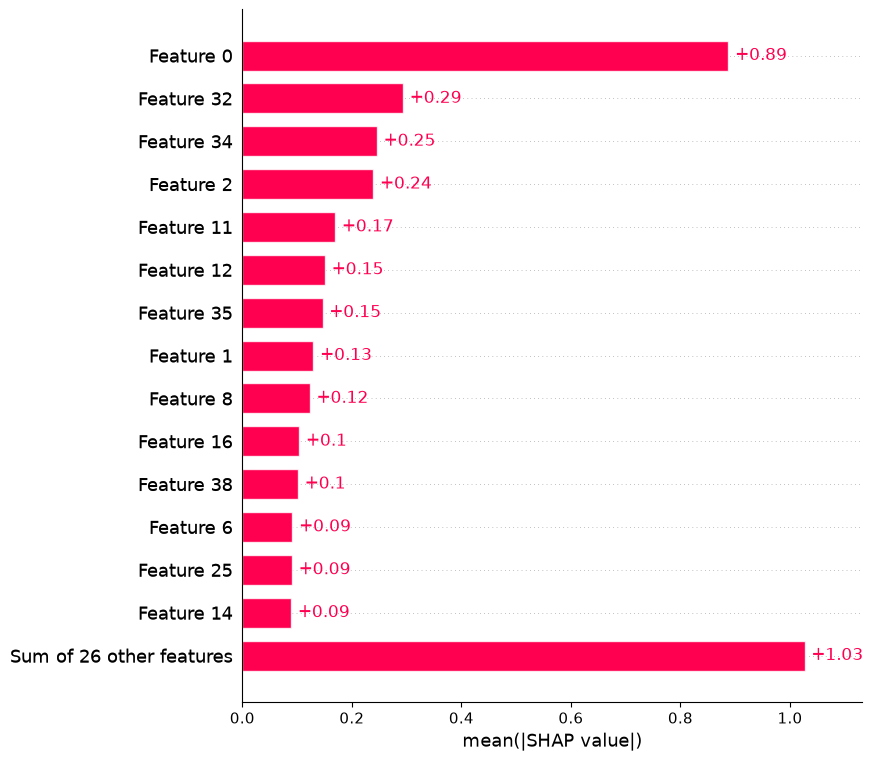

In [37]:
# # global feature importance
# shap.summary_plot(
#     shap_values,
#     X_test_transformed,
#     feature_names=feature_names
# )

# # shap bar plot
# shap.summary_plot(
#     shap_values,
#     X_test_transformed,
#     feature_names=feature_names,
#     plot_type="bar"
# )

# Global feature importance
shap.plots.bar(
    shap_values,
    max_display=15
)

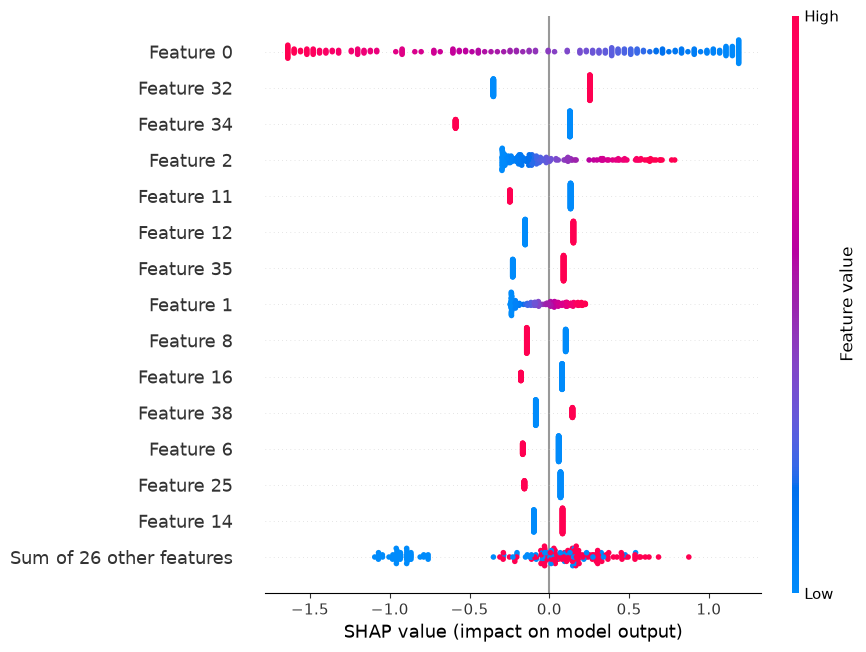

In [38]:
# Feature impact distribution
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

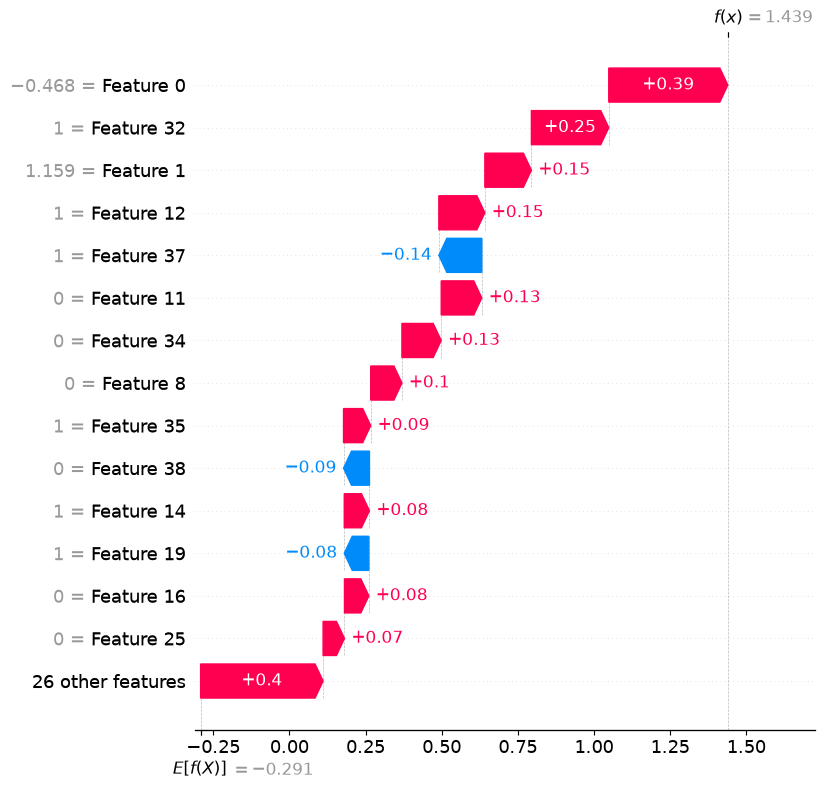

In [39]:
# Individual customer explanation
customer_idx = 5

shap.plots.waterfall(
    shap_values[customer_idx],
    max_display=15
)

In [40]:
# # explaining one individual customer
# customer_idx = 5
# base_value = float(np.squeeze(explainer.expected_value))
# shap.plots.waterfall(
#     shap.Explanation(
#         values=shap_values[customer_idx],
#         base_values=base_value,
#         data=X_test_transformed[customer_idx],
#         feature_names=feature_names
#     )
# )

## SHAP Explainability

SHAP was used to explain the predictions of the final Logistic Regression model.

The SHAP summary plot confirmed the findings obtained from the model coefficients:

- Month-to-month contracts had the strongest positive contribution towards churn.
- Longer customer tenure had the strongest negative contribution towards churn.
- Fibre optic internet service increased churn risk.
- Two-year contracts significantly reduced churn risk.
- Customers using technical support and online security services were less likely to churn.

The SHAP analysis provided both global and local explanations, helping to understand not only which features were important but also how they influenced individual customer predictions.

In [41]:
# saving the final model artifact
import joblib
import os

os.makedirs("../artifacts", exist_ok=True)

artifact = {
    'model':best_model,
    'threshold':float(best_threshold),
    'model_name': 'LogisticRegression',
    'features': X.columns.tolist()
}

joblib.dump(artifact, '../artifacts/churn_model.joblib')

print(f"[INFO] model artifact saved successfully")

[INFO] model artifact saved successfully


In [42]:
# verifying the saved model
artifact = joblib.load(
    "../artifacts/churn_model.joblib"
)

loaded_model = artifact["model"]
loaded_threshold = artifact["threshold"]

sample = X_test.iloc[:5]

probabilities = loaded_model.predict_proba(sample)[:, 1]

predictions = (
    probabilities >= loaded_threshold
).astype(int)

print("Probabilities:", probabilities)
print("Predictions:", predictions)

Probabilities: [0.11037002 0.85396307 0.16262954 0.65003112 0.06439983]
Predictions: [0 1 0 1 0]
